In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
from langgraph.types import Command
from state import BlogState
from agent import get_llm, researcher_agent, writer_agent, editor_agent
from graph import build_blog_graph

In [4]:
llm = get_llm()

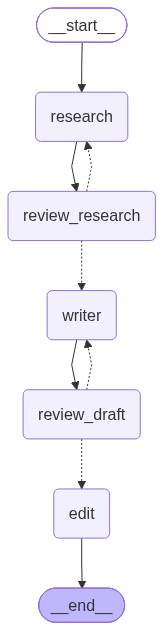

In [5]:
graph = build_blog_graph()
graph

In [6]:
config = {"configurable" : {"thread_id" : "4"}}

state = graph.invoke(
    {"topic":"Cryptocurrency Complience",
     "audience": "Complience Officers and biggners"},
    config=config
)

In [7]:
print(state)

{'topic': 'Cryptocurrency Complience', 'audience': 'Complience Officers and biggners', 'research': '**Research Outline – “Cryptocurrency Compliance: A Practical Guide for Compliance Officers and Beginners”**  \n\n---\n\n### 1. Introduction  \n- **1.1 Purpose & Audience** – Explain why the guide is needed for compliance officers (both seasoned and new) and newcomers to crypto.  \n- **1.2 Scope** – Define the geographic and regulatory scope (global overview with focus on major jurisdictions: US, EU, UK, Singapore, Japan, UAE, etc.).  \n- **1.3 Methodology** – Brief note on sources (regulatory texts, FATF guidance, industry best‑practice reports, blockchain‑analytics publications, enforcement actions).\n\n---\n\n### 2. Foundations of Cryptocurrency & Blockchain  \n- **2.1 Basic Concepts** – Digital assets, tokens, wallets, public/private keys, consensus mechanisms.  \n- **2.2 Types of Crypto Activities** – Exchanges, custodians, DeFi protocols, NFT marketplaces, payment processors, mixers

In [8]:
snap = graph.get_state(config)
interupt_payload = snap.interrupts[0].value
# interupt_payload
print("\n ...........\n")
print("Stage: ", interupt_payload.get("stage"))
print("\n ...........\n")
print("Research: ",interupt_payload.get("research"))


 ...........

Stage:  researcher_review

 ...........

Research:  **Research Outline – “Cryptocurrency Compliance: A Practical Guide for Compliance Officers and Beginners”**  

---

### 1. Introduction  
- **1.1 Purpose & Audience** – Explain why the guide is needed for compliance officers (both seasoned and new) and newcomers to crypto.  
- **1.2 Scope** – Define the geographic and regulatory scope (global overview with focus on major jurisdictions: US, EU, UK, Singapore, Japan, UAE, etc.).  
- **1.3 Methodology** – Brief note on sources (regulatory texts, FATF guidance, industry best‑practice reports, blockchain‑analytics publications, enforcement actions).

---

### 2. Foundations of Cryptocurrency & Blockchain  
- **2.1 Basic Concepts** – Digital assets, tokens, wallets, public/private keys, consensus mechanisms.  
- **2.2 Types of Crypto Activities** – Exchanges, custodians, DeFi protocols, NFT marketplaces, payment processors, mixers, stablecoins.  
- **2.3 Risk Profile Compared

In [9]:
# 1st Change -- Research level

# Human intervention --- Review the Blog
state = graph.invoke(
    Command(resume={"action": "revise", "feedback":"Re-write the blog title"}),
    config=config
)

In [10]:
snap = graph.get_state(config)
interupt_payload = snap.interrupts[0].value
# interupt_payload

# checking the stage
print("Stage: ", interupt_payload.get("stage"))

Stage:  researcher_review


In [11]:
print("\n ...........\n")
print("Topic: ", state.get("topic"))
print("\n ...........\n")
print("Feedback: ",state.get("research_feedback"))
print("\n ...........\n")
print("Research: ",state.get("research"))


 ...........

Topic:  Cryptocurrency Complience

 ...........

Feedback:  Re-write the blog title

 ...........

Research:  **Proposed Blog Title**  
*“Crypto Compliance 101: A Practical Guide for Officers and Newcomers”*  

---

## Research Outline  

### 1. Introduction  
- **1.1. Purpose of the guide** – why compliance matters in the crypto space.  
- **1.2. Target audience** – compliance officers, risk managers, and beginners.  
- **1.3. Scope** – regulatory landscape, AML/CFT obligations, operational best‑practices, and emerging risks.

### 2. Foundations of Crypto Compliance  
- **2.1. Key definitions** – cryptocurrency, digital asset, virtual asset service provider (VASP), AML, CFT.  
- **2.2. Core regulatory frameworks**  
  - FATF Recommendations (esp. Recommendation 15).  
  - EU MiCA (Markets in Crypto‑Assets Regulation).  
  - U.S. FinCEN guidance & the “Travel Rule”.  
  - Other notable jurisdictions (UK FCA, Singapore MAS, Japan FSA).  
- **2.3. Typical compliance obliga

In [12]:
# approve research
# It will only proceed once we will approve, otherwise each time go to back stage.
res2 = graph.invoke(Command(resume={"action":"approve", "feedback":""}),
             config=config)

This is 1st Attempt for you.


In [13]:
snap = graph.get_state(config)
interupt_payload = snap.interrupts[0].value
# interupt_payload

# checking the stage
print("Stage: ", interupt_payload.get("stage"))

Stage:  draft_review


In [14]:
print("\n ...........\n")
print("Topic: ", res2.get("topic"))
print("\n ...........\n")
print("Research: ",res2.get("research"))


 ...........

Topic:  Cryptocurrency Complience

 ...........

Research:  **Proposed Blog Title**  
*“Crypto Compliance 101: A Practical Guide for Officers and Newcomers”*  

---

## Research Outline  

### 1. Introduction  
- **1.1. Purpose of the guide** – why compliance matters in the crypto space.  
- **1.2. Target audience** – compliance officers, risk managers, and beginners.  
- **1.3. Scope** – regulatory landscape, AML/CFT obligations, operational best‑practices, and emerging risks.

### 2. Foundations of Crypto Compliance  
- **2.1. Key definitions** – cryptocurrency, digital asset, virtual asset service provider (VASP), AML, CFT.  
- **2.2. Core regulatory frameworks**  
  - FATF Recommendations (esp. Recommendation 15).  
  - EU MiCA (Markets in Crypto‑Assets Regulation).  
  - U.S. FinCEN guidance & the “Travel Rule”.  
  - Other notable jurisdictions (UK FCA, Singapore MAS, Japan FSA).  
- **2.3. Typical compliance obligations** – KYC/KYB, transaction monitoring, reporti

In [ ]:
# 2nd Change -- drfat level
res = graph.invoke(
    Command(resume={"action":"revise", "feedback": "keep the blog length 200-400 words"}),
    config=config
)
res

The human provided this feedback on your previous draft: keep the blog length 200-400 words. Apply changes while writing the draft.


{'topic': 'Cryptocurrency Complience',
 'audience': 'Complience Officers and biggners',
 'research': '**Proposed Blog Title**  \n*“Crypto Compliance 101: A Practical Guide for Officers and Newcomers”*  \n\n---\n\n## Research Outline  \n\n### 1. Introduction  \n- **1.1. Purpose of the guide** – why compliance matters in the crypto space.  \n- **1.2. Target audience** – compliance officers, risk managers, and beginners.  \n- **1.3. Scope** – regulatory landscape, AML/CFT obligations, operational best‑practices, and emerging risks.\n\n### 2. Foundations of Crypto Compliance  \n- **2.1. Key definitions** – cryptocurrency, digital asset, virtual asset service provider (VASP), AML, CFT.  \n- **2.2. Core regulatory frameworks**  \n  - FATF Recommendations (esp. Recommendation\u202f15).  \n  - EU MiCA (Markets in Crypto‑Assets Regulation).  \n  - U.S. FinCEN guidance & the “Travel Rule”.  \n  - Other notable jurisdictions (UK FCA, Singapore MAS, Japan FSA).  \n- **2.3. Typical compliance oblig

In [26]:
print(res["draft"])

# Crypto Compliance 101: A Practical Guide for Officers and Newcomers  

## Introduction  
Compliance is the backbone of a trustworthy crypto ecosystem. Whether you’re a seasoned compliance officer, a risk manager, or just starting out, understanding the regulatory expectations and operational safeguards is essential to protect your organization and its customers.

## Foundations of Crypto Compliance  
- **Key terms** – *cryptocurrency*, *digital asset*, *virtual asset service provider (VASP)*, *AML* (anti‑money‑laundering) and *CFT* (counter‑terrorist financing).  
- **Core frameworks** – The FATF Recommendations (especially Recommendation 15) set the global baseline for VASPs. In Europe, the Markets in Crypto‑Assets Regulation (MiCA) creates a harmonised regime, while U.S. FinCEN’s guidance enforces the “Travel Rule” for cross‑border transfers. Other jurisdictions such as the UK FCA, Singapore MAS and Japan FSA have issued comparable expectations.  
- **Typical obligations** – KYC/KY

In [16]:
# approve draft
# It will only proceed once we will approve, otherwise each time go to back stage.
res3 = graph.invoke(Command(resume={"action":"approve", "feedback":""}),
             config=config)

In [24]:
# snap = graph.get_state(config)
# interupt_payload = snap.interrupts[0].value

# print(interupt_payload)
# print("Stage: ", interupt_payload.get("stage"))

In [29]:
print("\n ...........\n")
print("Topic: ", res3.get("topic"))
print("\n ...........\n")
print("Research: ",res3.get("draft"))


 ...........

Topic:  Cryptocurrency Complience

 ...........

Research:  # Crypto Compliance 101: A Practical Guide for Officers and Newcomers  

## Introduction  
Compliance is the backbone of a trustworthy crypto ecosystem. Whether you’re a seasoned compliance officer, a risk manager, or just starting out, understanding the regulatory expectations and operational safeguards is essential to protect your organization and its customers.

## Foundations of Crypto Compliance  
- **Key terms** – *cryptocurrency*, *digital asset*, *virtual asset service provider (VASP)*, *AML* (anti‑money‑laundering) and *CFT* (counter‑terrorist financing).  
- **Core frameworks** – The FATF Recommendations (especially Recommendation 15) set the global baseline for VASPs. In Europe, the Markets in Crypto‑Assets Regulation (MiCA) creates a harmonised regime, while U.S. FinCEN’s guidance enforces the “Travel Rule” for cross‑border transfers. Other jurisdictions such as the UK FCA, Singapore MAS and Japan FS

In [30]:
res4 = graph.invoke(Command(resume={"action":"approve", "feedback":""}),
             config=config)

In [ ]:
print(res4.get("final_blog"))

'# Crypto Compliance\u202f101: A Practical Guide for Officers and Newcomers  \n\n## Introduction  \nCompliance is the backbone of a trustworthy crypto ecosystem. Whether you’re a seasoned compliance officer, a risk manager, or just starting out, knowing the regulatory expectations and operational safeguards is essential to protect your organization and its customers.\n\n## Foundations of Crypto Compliance  \n- **Key terms** – *cryptocurrency*, *digital asset*, *virtual asset service provider (VASP)*, *AML* (anti‑money‑laundering) and *CFT* (counter‑terrorist financing).  \n- **Core frameworks** – The FATF Recommendations (especially Recommendation\u202f15) set the global baseline for VASPs. In Europe, the Markets in Crypto‑Assets Regulation (MiCA) creates a harmonised regime, while U.S. FinCEN’s guidance enforces the “Travel Rule” for cross‑border transfers. Other jurisdictions such as the UK FCA, Singapore MAS and Japan FSA have issued comparable expectations.  \n- **Typical obligatio

In [18]:
# snap = graph.get_state(config)
# interupt_payload = snap.interrupts[0].value
# # interupt_payload

# # checking the stage
# print("Stage: ", interupt_payload.get("stage"))


In [19]:
# Now we will aprove
# It will only proceed once we will approve, otherwise each time go back stage.
# res2 = graph.invoke(Command(resume={"action":"approve", "feedback":""}),
#              config=config)

In [20]:
# res2